<a href="https://colab.research.google.com/github/NatShed/-/blob/main/attack_CovidXray.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Модель загружена
Всего найдено изображений: 2730
[clean ] Accuracy: 0.8253 | Recall: 0.7894 | F1: 0.8764
[rotate] Accuracy: 0.7586 | Recall: 0.7031 | F1: 0.8205
[noise ] Accuracy: 0.7674 | Recall: 0.7124 | F1: 0.8278
[blur  ] Accuracy: 0.8623 | Recall: 0.8389 | F1: 0.9053
[patch ] Accuracy: 0.8051 | Recall: 0.7628 | F1: 0.8600
[elastic] Accuracy: 0.7333 | Recall: 0.6671 | F1: 0.7970
[contrast] Accuracy: 0.7659 | Recall: 0.7199 | F1: 0.8284
[all   ] Accuracy: 0.6784 | Recall: 0.6354 | F1: 0.7561

График с примерами сохранен в файл 'augmentation_examples.png'


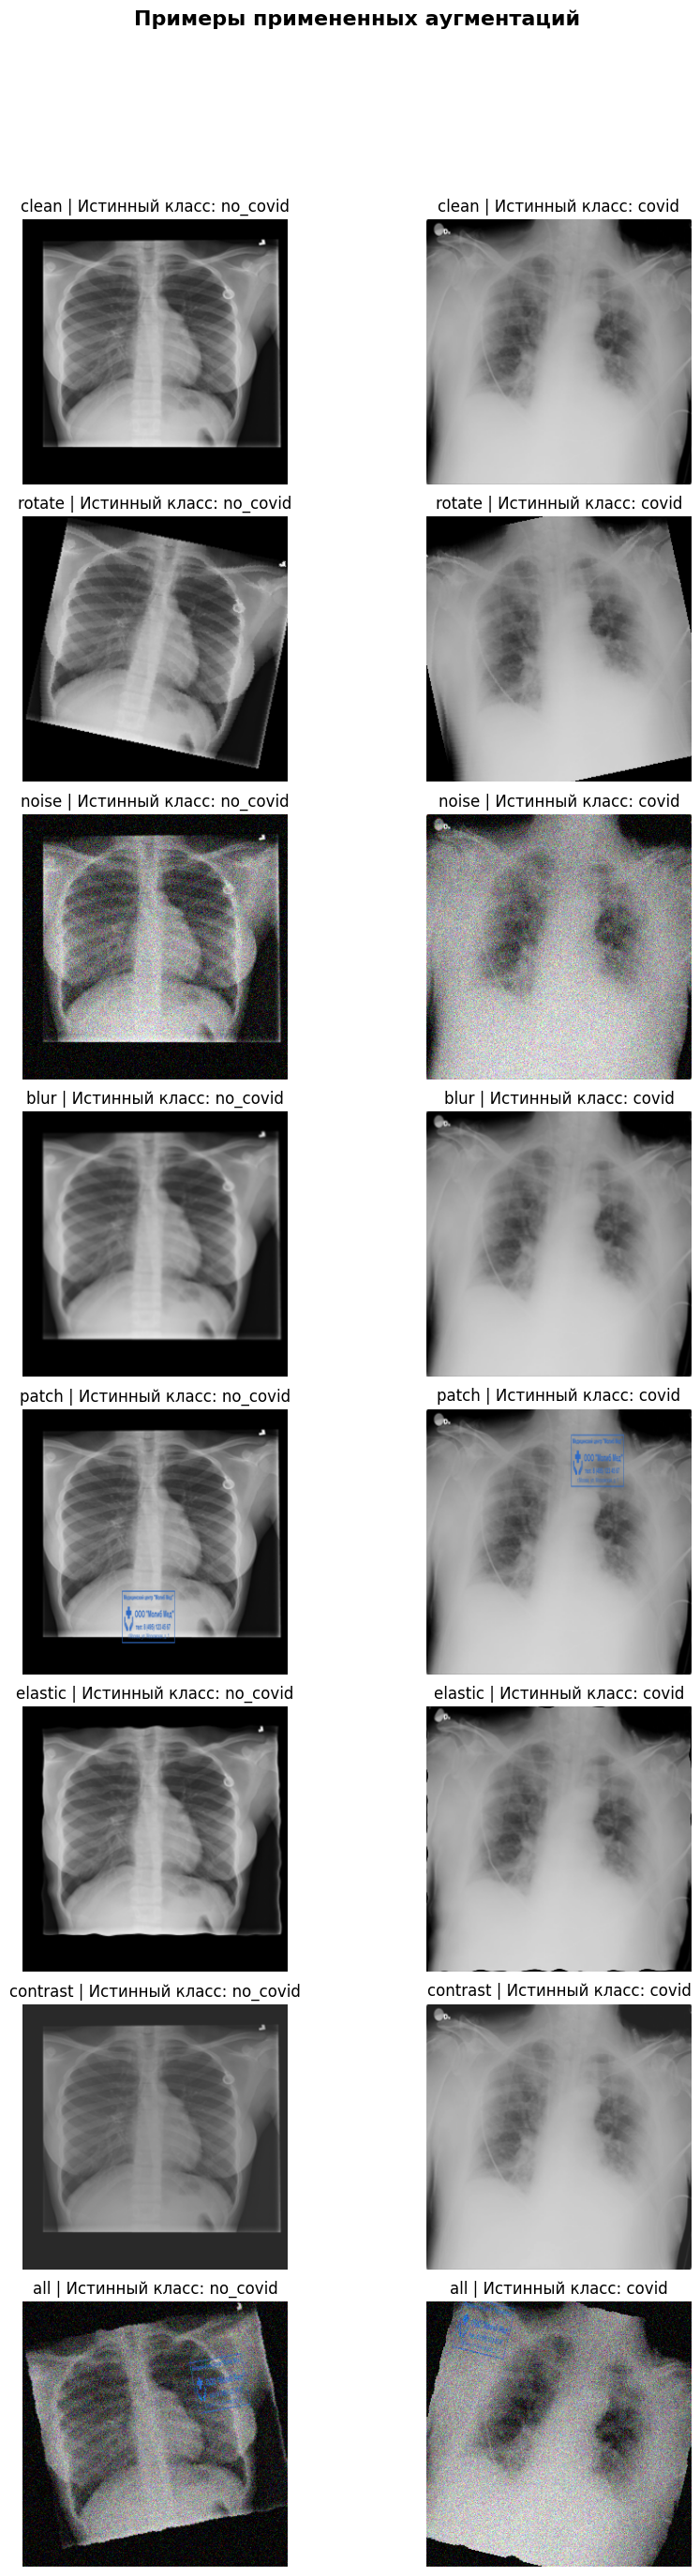

In [ ]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
from pathlib import Path
from PIL import Image
from torchvision import transforms, models
import matplotlib.pyplot as plt

# ==========================================
# 1. НАСТРОЙКИ И ЗАГРУЗКА МОДЕЛИ
# ==========================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASS_NAMES = {0: "no_covid", 1: "covid"}

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

def load_model(pth_path, num_classes=2, device=DEVICE):
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    state = torch.load(pth_path, map_location=device)
    model.load_state_dict(state)
    model.to(device)
    model.eval()
    return model

robust_model = load_model("robust_finetuned_best.pth")
print("Модель загружена")

# ==========================================
# 2. ФУНКЦИИ АУГМЕНТАЦИИ
# ==========================================
aug_rotate = transforms.RandomRotation(degrees=15, fill=0)
aug_blur = transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 2.0))
aug_elastic = transforms.ElasticTransform(alpha=50.0, sigma=5.0)
aug_contrast = transforms.ColorJitter(contrast=(0.5, 2.0), brightness=(0.8, 1.2))
def add_noise(img):
    img_arr = np.array(img).astype(np.float32)
    noise = np.random.normal(0, 25, img_arr.shape)
    img_arr = np.clip(img_arr + noise, 0, 255).astype(np.uint8)
    return Image.fromarray(img_arr)

def add_patch(img, patch_img, patch_size=(60, 60)):
    img = img.copy()
    patch_resized = patch_img.resize(patch_size)

    x = random.randint(0, max(0, img.width - patch_size[0]))
    y = random.randint(0, max(0, img.height - patch_size[1]))

    if patch_resized.mode == "RGBA":
        img.paste(patch_resized, (x, y), mask=patch_resized)
    else:
        img.paste(patch_resized, (x, y))
    return img

try:
    patch_img = Image.open("patch.png").convert("RGBA")
except FileNotFoundError:
    print("ВНИМАНИЕ: patch.png не найден. Тест с патчем будет пропущен.")
    patch_img = None

def predict_pil_image(model, img_pil):
    x = preprocess(img_pil).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
    pred = int(np.argmax(probs))
    return pred, probs

# ==========================================
# 3. ПОДГОТОВКА ДАННЫХ
# ==========================================
COVID_DIR  = Path("drive/MyDrive/xrayData/covid")
NORMAL_DIR = Path("drive/MyDrive/xrayData/no covid")

dataset = []
for folder, true_label in [(COVID_DIR, 1), (NORMAL_DIR, 0)]:
    files = sorted(folder.glob("*.png"))
    for p in files:
        dataset.append((p, true_label))

print(f"Всего найдено изображений: {len(dataset)}")

scenarios = ["clean", "rotate", "noise", "blur", "patch", "elastic", "contrast", "all"]
results = {}

# Словарь для хранения примеров изображений: examples[scenario][true_label] = img
examples_to_show = {sc: {} for sc in scenarios}

random.seed(42)
np.random.seed(42)

# ==========================================
# 4. ЗАПУСК ТЕСТОВ И СБОР ПРИМЕРОВ
# ==========================================
for scenario in scenarios:
    if scenario == "patch" and patch_img is None:
        continue

    y_true, y_pred = [], []

    for img_path, true_label in dataset:
        img = Image.open(img_path).convert("RGB")

        # Применяем аугментации
        if scenario in ["elastic", "all"]:
            img = aug_elastic(img)
        if scenario in ["contrast", "all"]:
            img = aug_contrast(img)
        if scenario in ["patch", "all"] and patch_img is not None:
            img = add_patch(img, patch_img)
        if scenario in ["rotate", "all"]:
            img = aug_rotate(img)
        if scenario in ["noise", "all"]:
            img = add_noise(img)
        if scenario in ["blur", "all"]:
            img = aug_blur(img)

        # Сохраняем ПЕРВЫЙ попавшийся пример для каждого класса (0 и 1)
        if true_label not in examples_to_show[scenario]:
            examples_to_show[scenario][true_label] = img.copy()

        pred, _ = predict_pil_image(robust_model, img)
        y_true.append(true_label)
        y_pred.append(pred)

    # Считаем метрики
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    acc = (y_true == y_pred).mean()
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    results[scenario] = {"Accuracy": acc, "Precision": precision, "Recall": recall, "F1": f1}
    print(f"[{scenario:6}] Accuracy: {acc:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")

# ==========================================
# 5. ВИЗУАЛИЗАЦИЯ ПРИМЕРОВ
# ==========================================
# Отфильтровываем сценарии, для которых нет картинок (например, если забыли patch.png)
valid_scenarios = [sc for sc in scenarios if sc in examples_to_show and len(examples_to_show[sc]) > 0]
num_rows = len(valid_scenarios)

fig, axes = plt.subplots(num_rows, 2, figsize=(10, 3.5 * num_rows))
fig.suptitle('Примеры примененных аугментаций', fontsize=16, fontweight='bold')

for i, scenario in enumerate(valid_scenarios):
    for j, cls in enumerate([0, 1]):
        ax = axes[i][j]
        if cls in examples_to_show[scenario]:
            ax.imshow(examples_to_show[scenario][cls])
            ax.set_title(f"{scenario} | Истинный класс: {CLASS_NAMES[cls]}")
        else:
            ax.set_title(f"{scenario} | Нет примера")
        ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.90)
plt.savefig("augmentation_examples.png", dpi=150)
print("\nГрафик с примерами сохранен в файл 'augmentation_examples.png'")
plt.show()

Ищем примеры, где аугментация сломала предсказание...
Найдено успешных атак аугментациями: 10
График сохранен в файл 'successful_augmentations_examples.png'


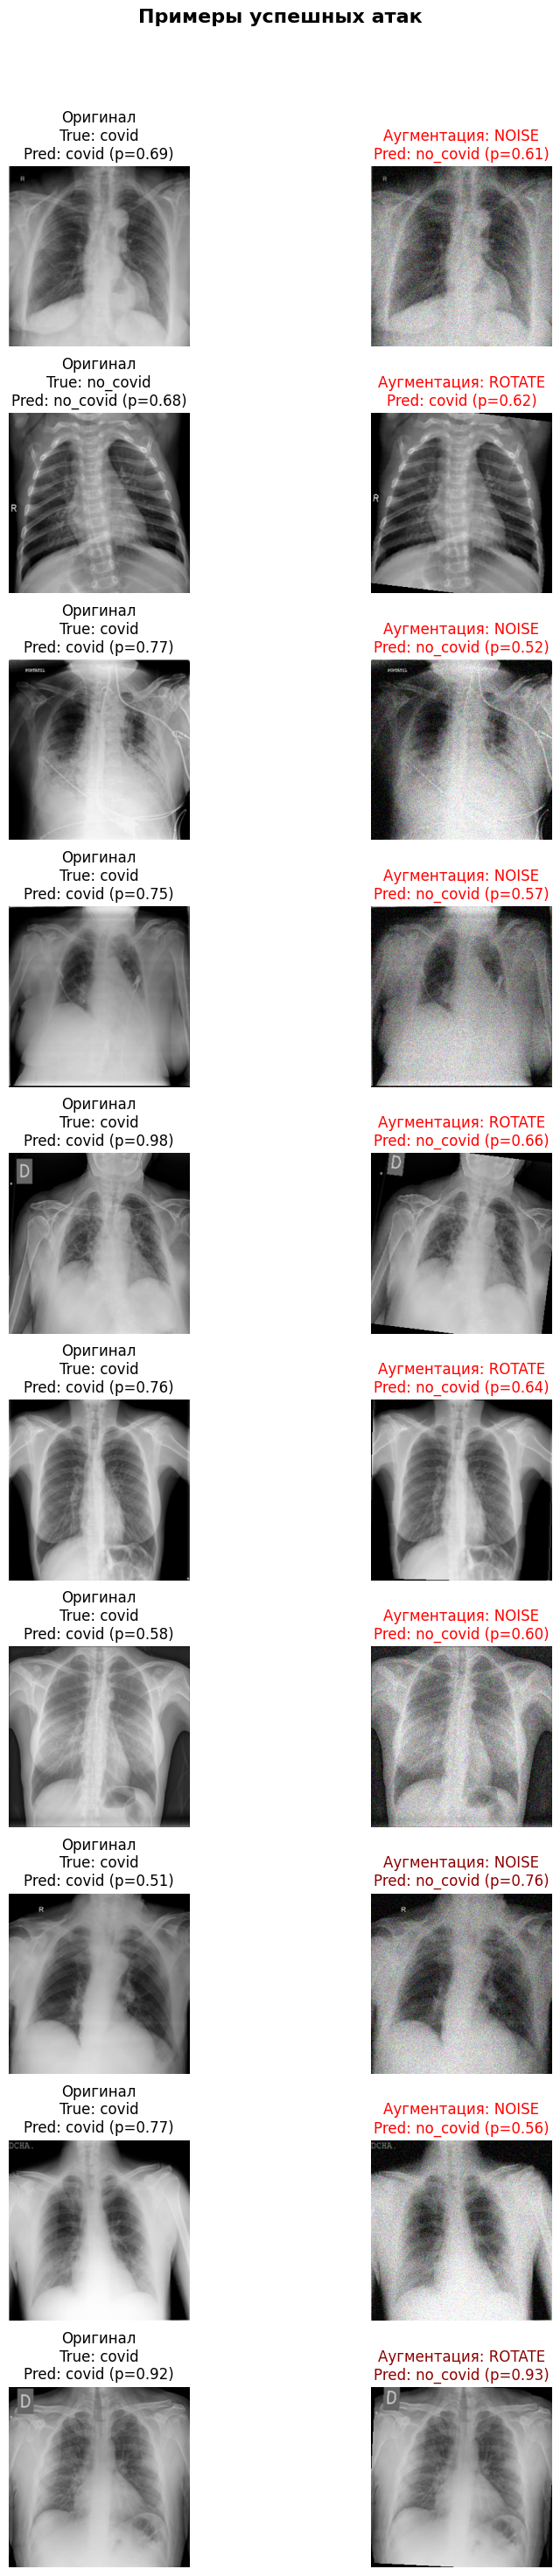

In [ ]:
import matplotlib.pyplot as plt
import random

# Создаем список доступных аугментаций (функций)
available_augmentations = [
    ("rotate", lambda img: aug_rotate(img)),
    ("noise", lambda img: add_noise(img)),
    ("blur", lambda img: aug_blur(img))
]

# Добавляем патч, если он был загружен ранее
if patch_img is not None:
    available_augmentations.append(("patch", lambda img: add_patch(img, patch_img)))

# ==========================================
# ПОИСК 10 УСПЕШНЫХ АУГМЕНТАЦИЙ
# ==========================================
successful_augs = []
print("Ищем примеры, где аугментация сломала предсказание...")

# Перемешаем датасет, чтобы найти примеры из разных папок
random.seed(42)
random.shuffle(dataset)

for img_path, true_label in dataset:
    if len(successful_augs) >= 10:
        break # Набрали 10 штук — останавливаемся

    img = Image.open(img_path).convert("RGB")

    # 1. Предсказание на чистой картинке
    x_clean = preprocess(img).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        clean_logits = robust_model(x_clean)
        clean_probs = torch.softmax(clean_logits, dim=1).cpu().numpy()[0]
    clean_pred = int(np.argmax(clean_probs))

    # Нас интересуют только те картинки, где модель изначально была ПРАВА
    if clean_pred != true_label:
        continue

    # 2. Выбираем случайную аугментацию и применяем
    aug_name, aug_func = random.choice(available_augmentations)
    img_aug = aug_func(img)

    # 3. Предсказание на аугментированной картинке
    x_aug = preprocess(img_aug).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        aug_logits = robust_model(x_aug)
        aug_probs = torch.softmax(aug_logits, dim=1).cpu().numpy()[0]
    aug_pred = int(np.argmax(aug_probs))

    # Если аугментация сработала (предсказание изменилось на неправильное)
    if aug_pred != true_label:
        successful_augs.append({
            "original_img": img,
            "aug_img": img_aug, # Сохраняем уже готовую PIL-картинку
            "aug_name": aug_name,
            "true_label": true_label,
            "clean_pred": clean_pred,
            "clean_prob": clean_probs[clean_pred],
            "aug_pred": aug_pred,
            "aug_prob": aug_probs[aug_pred]
        })

print(f"Найдено успешных атак аугментациями: {len(successful_augs)}")

# ==========================================
# ВИЗУАЛИЗАЦИЯ РЕЗУЛЬТАТОВ
# ==========================================
if len(successful_augs) > 0:
    fig, axes = plt.subplots(len(successful_augs), 2, figsize=(10, 3 * len(successful_augs)))
    fig.suptitle('Примеры успешных атак', fontsize=16, fontweight='bold')

    # Если нашли только 1 пример, axes будет одномерным
    if len(successful_augs) == 1:
        axes = [axes]

    for i, aug in enumerate(successful_augs):
        # Левая колонка: Оригинал
        axes[i][0].imshow(aug["original_img"])
        axes[i][0].set_title(
            f"Оригинал\nTrue: {CLASS_NAMES[aug['true_label']]}\n"
            f"Pred: {CLASS_NAMES[aug['clean_pred']]} (p={aug['clean_prob']:.2f})"
        )
        axes[i][0].axis('off')

        # Правая колонка: Аугментированная картинка
        axes[i][1].imshow(aug["aug_img"])

        # Красим заголовок в зависимости от того, насколько уверенно модель ошиблась
        color = 'darkred' if aug['aug_prob'] > 0.7 else 'red'

        axes[i][1].set_title(
            f"Аугментация: {aug['aug_name'].upper()}\n"
            f"Pred: {CLASS_NAMES[aug['aug_pred']]} (p={aug['aug_prob']:.2f})",
            color=color
        )
        axes[i][1].axis('off')

    plt.tight_layout()
    plt.subplots_adjust(top=0.92)
    plt.savefig("successful_augmentations_examples.png", dpi=150)
    print("График сохранен в файл 'successful_augmentations_examples.png'")
    plt.show()

Запускаем исправленную JSMA атаку (это может занять пару минут)...
Найдено успешных JSMA атак: 10
График сохранен в файл 'jsma_attacks_examples.png'


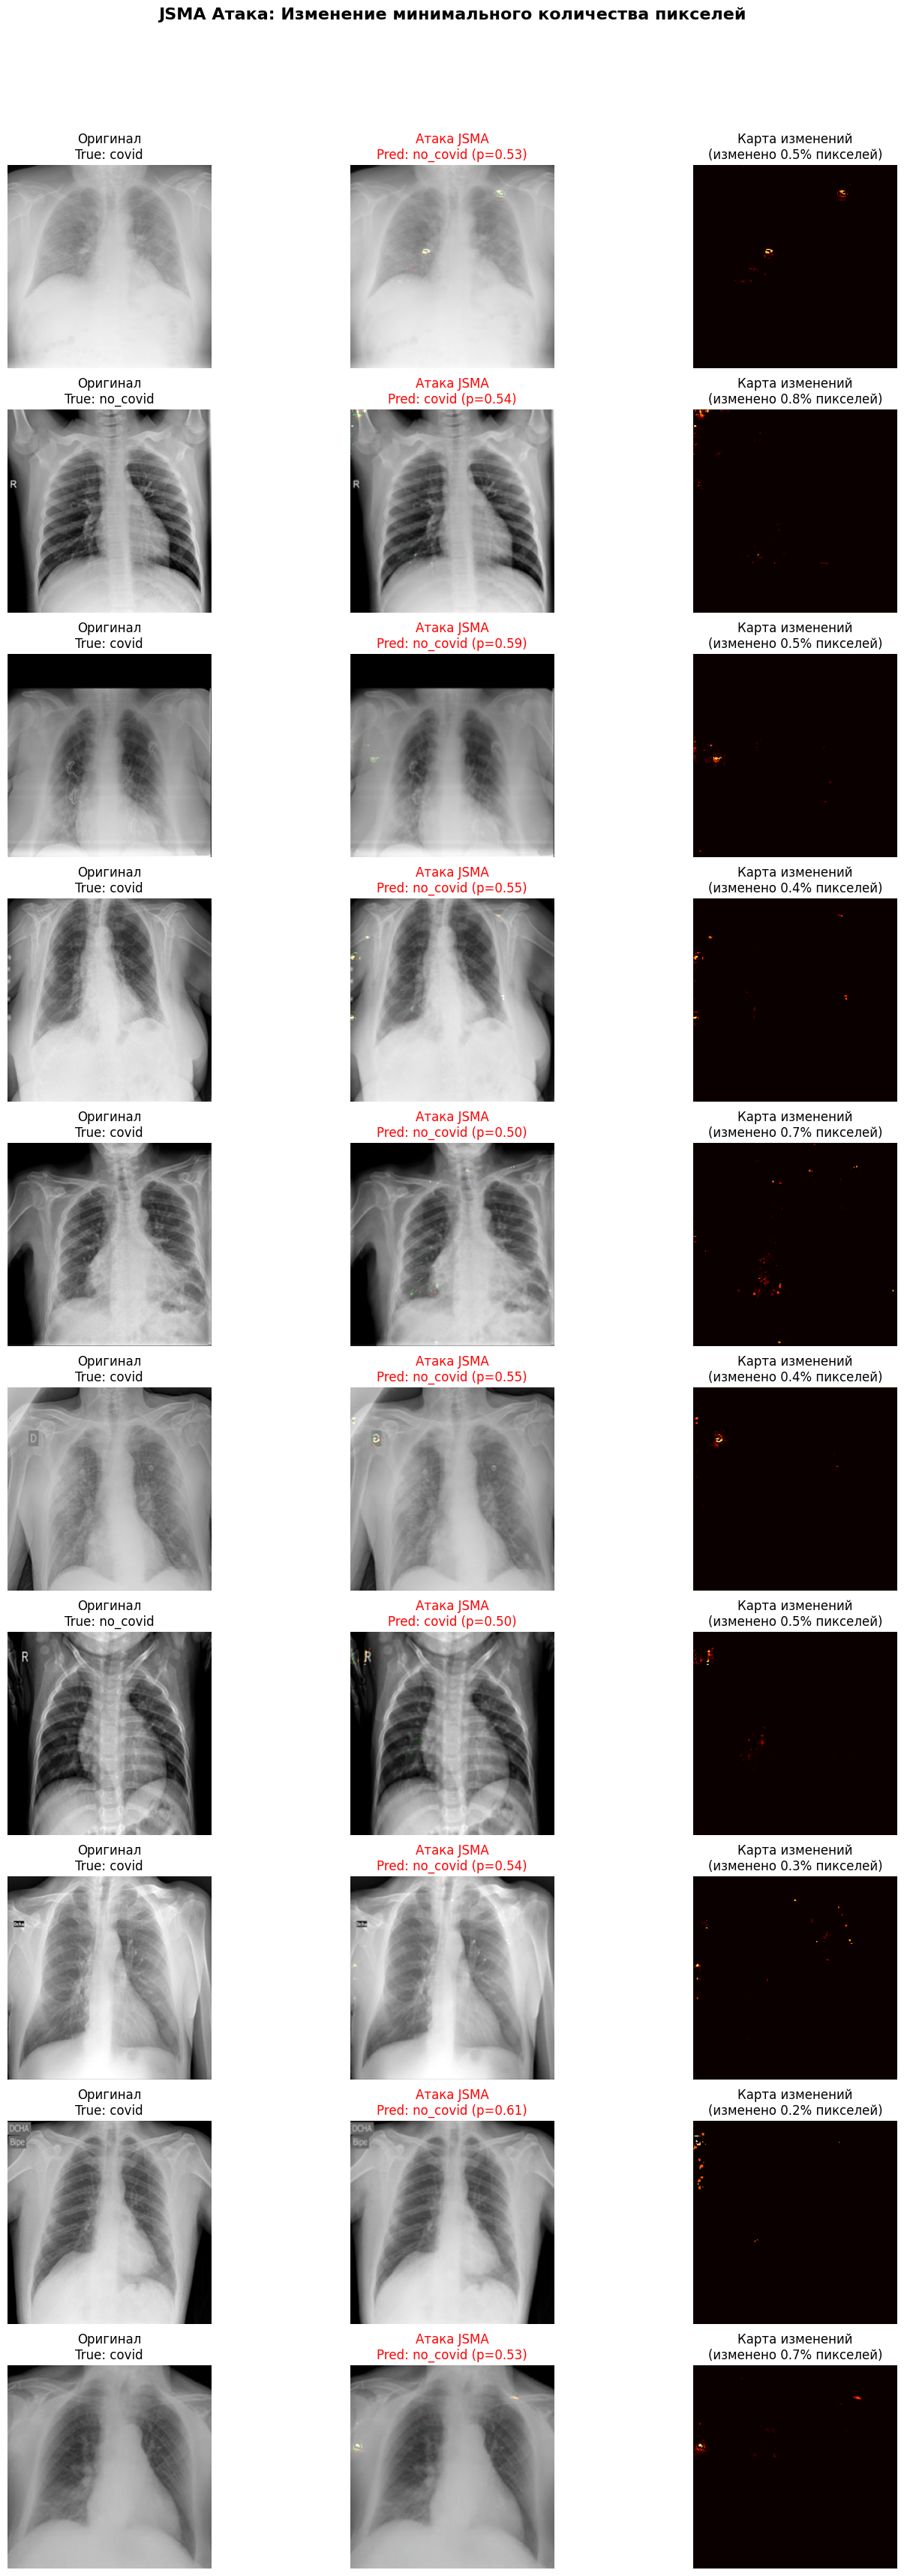

In [ ]:
import torch.nn.functional as F
import matplotlib.pyplot as plt

def jsma_attack(model, image_tensor, target_label, theta=0.1, top_k=50, max_iter=30):

    x_adv = image_tensor.clone().detach().to(DEVICE)
    min_val = -2.2
    max_val = 2.7

    for i in range(max_iter):
        x_adv.requires_grad = True
        logits = model(x_adv)

        # Если атака уже сработала, выходим
        if torch.argmax(logits) == target_label:
            break

        target_logit = logits[0, target_label]
        other_logit = logits[0, 1 - target_label]

        model.zero_grad()

        # Считаем градиенты
        grad_target = torch.autograd.grad(target_logit, x_adv, retain_graph=True)[0]
        grad_other = torch.autograd.grad(other_logit, x_adv, retain_graph=True)[0]

        # Формула Saliency Map
        saliency = torch.where((grad_target > 0) & (grad_other < 0),
                               grad_target * torch.abs(grad_other),
                               torch.zeros_like(grad_target))

        # Спускаем размерность и находим индексы top_k самых важных пикселей
        saliency_flat = saliency.view(-1)
        topk_indices = torch.topk(saliency_flat, k=top_k).indices

        # ИСПРАВЛЕНИЕ: Создаем маску вместо изменения на месте (in-place)
        perturbation = torch.zeros_like(saliency_flat)
        perturbation[topk_indices] = theta
        perturbation = perturbation.view(1, 3, 224, 224)

        # Прибавляем маску к изображению (detach() нужен, чтобы разорвать граф для следующей итерации)
        x_adv = x_adv.detach() + perturbation

        # Клиппируем
        x_adv = torch.clamp(x_adv, min_val, max_val)

    return x_adv.detach()

# ==========================================
# ПОИСК 10 УСПЕШНЫХ JSMA АТАК
# ==========================================
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

def tensor_to_img(tensor):
    img = inv_normalize(tensor.squeeze(0).cpu()).clamp(0, 1)
    return img.permute(1, 2, 0).numpy()

successful_jsma = []
print("Запускаем исправленную JSMA атаку (это может занять пару минут)...")

random.seed(42)
random.shuffle(dataset)

for img_path, true_label in dataset:
    if len(successful_jsma) >= 10:
        break

    img = Image.open(img_path).convert("RGB")
    x_norm = preprocess(img).unsqueeze(0).to(DEVICE)

    # 1. Проверяем, что модель изначально права
    with torch.no_grad():
        clean_probs = torch.softmax(robust_model(x_norm), dim=1).cpu().numpy()[0]
    clean_pred = int(np.argmax(clean_probs))

    if clean_pred != true_label:
        continue

    # 2. Запускаем JSMA
    target_label = 1 - true_label
    x_adv = jsma_attack(robust_model, x_norm, target_label, theta=0.15, top_k=100, max_iter=25)

    # 3. Проверяем результат
    with torch.no_grad():
        adv_probs = torch.softmax(robust_model(x_adv), dim=1).cpu().numpy()[0]
    adv_pred = int(np.argmax(adv_probs))

    if adv_pred == target_label:
        # Вычисляем разницу (карту изменений)
        diff = torch.abs(x_adv - x_norm).sum(dim=1).squeeze(0).cpu().numpy()

        successful_jsma.append({
            "original_img": img,
            "adv_img": tensor_to_img(x_adv),
            "diff_map": diff,
            "true_label": true_label,
            "adv_pred": adv_pred,
            "adv_prob": adv_probs[adv_pred],
            "changed_pixels_percent": (diff > 0).mean() * 100
        })

print(f"Найдено успешных JSMA атак: {len(successful_jsma)}")

# ==========================================
# ВИЗУАЛИЗАЦИЯ
# ==========================================
if len(successful_jsma) > 0:
    fig, axes = plt.subplots(len(successful_jsma), 3, figsize=(15, 3.5 * len(successful_jsma)))
    fig.suptitle('JSMA Атака: Изменение минимального количества пикселей', fontsize=16, fontweight='bold')

    if len(successful_jsma) == 1:
        axes = [axes]

    for i, attack in enumerate(successful_jsma):
        axes[i][0].imshow(attack["original_img"])
        axes[i][0].set_title(f"Оригинал\nTrue: {CLASS_NAMES[attack['true_label']]}")
        axes[i][0].axis('off')

        axes[i][1].imshow(attack["adv_img"])
        axes[i][1].set_title(f"Атака JSMA\nPred: {CLASS_NAMES[attack['adv_pred']]} (p={attack['adv_prob']:.2f})", color='red')
        axes[i][1].axis('off')

        axes[i][2].imshow(attack["diff_map"], cmap='hot')
        axes[i][2].set_title(f"Карта изменений\n(изменено {attack['changed_pixels_percent']:.1f}% пикселей)")
        axes[i][2].axis('off')

    plt.tight_layout()
    plt.subplots_adjust(top=0.92)
    plt.savefig("jsma_attacks_examples.png", dpi=150)
    print("График сохранен в файл 'jsma_attacks_examples.png'")
    plt.show()
